In [1]:
import numpy as np
from matplotlib import pyplot as plt
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
from scipy.sparse.linalg import svds

In [29]:
n_timepoints = 5000
series = np.zeros(n_timepoints)

x = 0
a = 0.9

b = 0

firing_prop = 0.001
spikes = (np.random.rand(n_timepoints) < firing_prop).astype(float)

for i in range(2, n_timepoints):
    series[i] = (a * series[i - 1]) + (b * series[i - 2]) + (50 * spikes[i])

<StemContainer object of 3 artists>

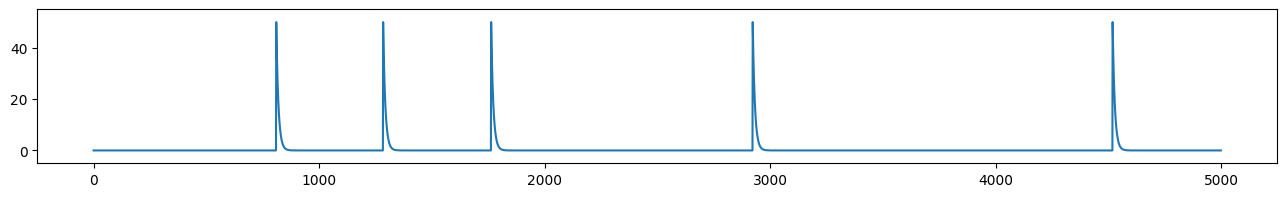

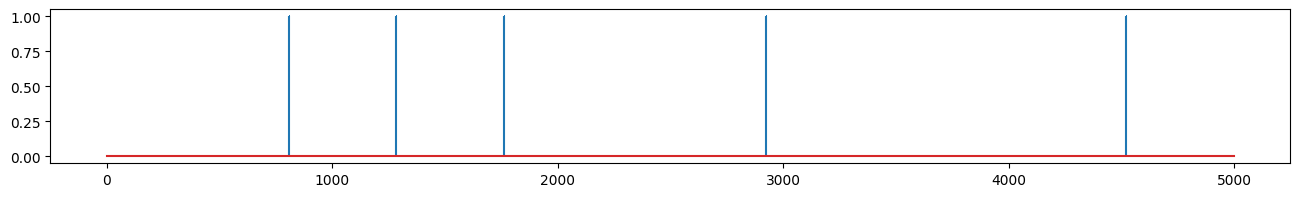

In [30]:
fig = plt.figure(figsize=(16, 2))
plt.plot(series)
plt.ylim(series.min() - 5, series.max() + 5)

fig = plt.figure(figsize=(16, 2))
plt.stem(spikes, markerfmt=",")

(-86.58199314311476, 116.52693068927431)

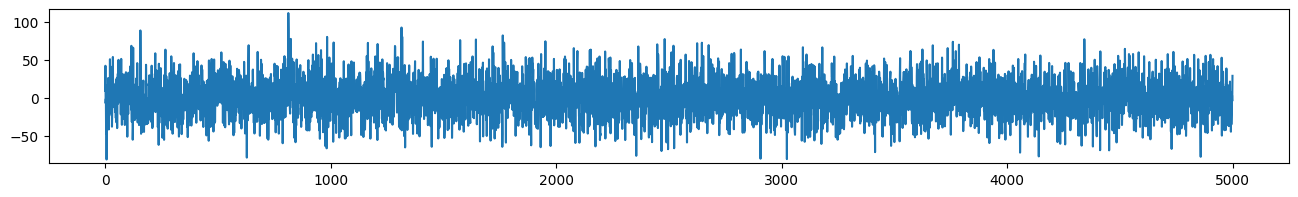

In [149]:
series_noise = series + np.random.normal(scale=25, size=series.size)

fig = plt.figure(figsize=(16, 2))
plt.plot(series_noise)
plt.ylim(series_noise.min() - 5, series_noise.max() + 5)

In [150]:
trace = series_noise

In [151]:
def get_hankel(s: np.ndarray, timepoint: int, n_steps: int):
    h = np.zeros((n_steps, n_steps), dtype=np.float32)
    for i in range(n_steps):
        start = timepoint + i
        stop = start + n_steps
        h[i] = s[start:stop]

    return h

In [152]:
trace = trace[::-1]

In [153]:
singular_vals = np.zeros(n_timepoints)
n_steps = 20

for i in range(n_steps, n_timepoints - (n_steps * 2)):
    h = get_hankel(trace, timepoint=i - n_steps, n_steps=n_steps)
    u, s, v = svds(h)
    singular_vals[i] = s.max()

# singular_vals = singular_vals[::-1]
# trace = trace[::-1]

<StemContainer object of 3 artists>

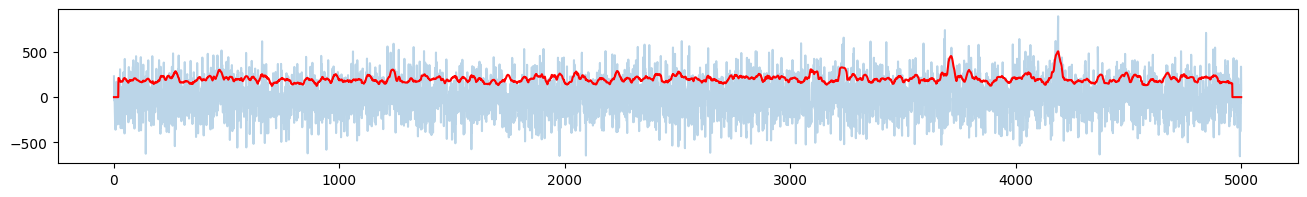

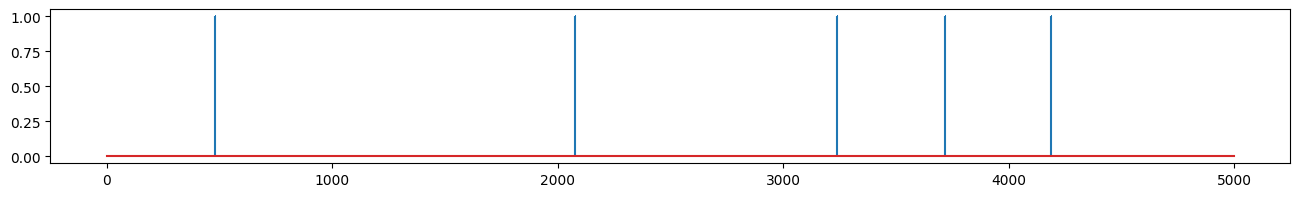

In [155]:
fig = plt.figure(figsize=(16, 2))
plt.plot(trace * 8, alpha=0.3)
plt.plot(singular_vals, color="r")

fig = plt.figure(figsize=(16, 2))
plt.stem(spikes[::-1], markerfmt=",")

[]

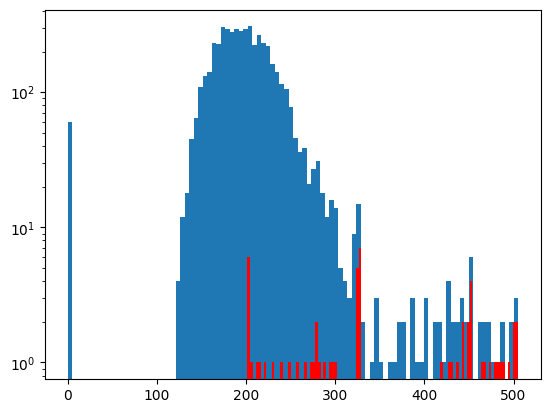

In [156]:
plt.hist(singular_vals, bins=100)
plt.hist(singular_vals[np.where(series[::-1] > 15)], bins=100, color="r")
plt.semilogy()

In [126]:
singular_vals.std()

44.776347402447676

In [122]:
gp = fpl.GridPlot((4, 1), names=[["series"], ["hankel"], ["v"], ["singular-values"]])

series_line = gp["series"].add_line(trace, name="line_series", colors="blue", alpha=0.5)
series_clean = gp["series"].add_line(series[::-1], name="line_clean", alpha=0.5)
sel = series_line.add_linear_selector()

singular_values_line = gp["series"].add_line(singular_vals / 9, colors="r", name="line_svals")

hankel = get_hankel(trace, timepoint=0, n_steps=20)
img = gp["hankel"].add_image(hankel, name="hankel")
img.cmap.vmax = series.max()

def update_hankel(ev):
    ix = ev.pick_info["selected_index"]
    # if ix > 461:
    #     return
    hankel = get_hankel(trace, timepoint=ix - 20, n_steps=20)
    img.data = hankel

    u, s, v = svds(hankel)
    gp["singular-values"].clear()
    gp["singular-values"].add_scatter(np.column_stack([np.arange(s.size), s[::-1]]), sizes=10)
    gp["singular-values"].auto_scale()

    gp["v"].clear()
    gp["v"].add_line(v[::-1][0])
    gp["v"].auto_scale()

sel.selection.add_event_handler(update_hankel)

gp.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [69]:
sel.selection()

2051.0072296646476

In [70]:
sel.selection()

2076.0138400863466